# 🛰️ Landsat / Sentinel-2 Overpass Prediction Notebook: Overview
## **ROI Definition → Orbit Propagation → Swath Intersection → UTC/Local-Time Report**

This notebook is the **core prediction engine** of the workflow. Give it a Region of Interest and a time window and it tells you **when Landsat 8, Landsat 9 and Sentinel-2A/B/C will image that area**, how much of the ROI each pass covers, and when that happens in both **UTC** and the **ROI's own local time**, then writes the result to CSV.

> 🧭 **How this differs from n2yo.com**: n2yo reports when a satellite is *above your horizon*, which for a polar orbiter happens several times a day and says nothing about whether your area is imaged. This workflow intersects each satellite's **instrument swath** (Sentinel-2 MSI ≈ 290 km, Landsat OLI ≈ 185 km) with your ROI, so every row is a pass in which the sensor footprint actually covers the ROI.

---

### 🚀 Core Functional Areas
* **Orbit Propagation**: Current TLEs from CelesTrak, propagated with SGP4 (Skyfield) in a 30 s coarse scan followed by a 1 s refinement.
* **Swath-Aware Imaging Test**: Cross-track scan lines are built geodesically from the ground-track heading and intersected with the ROI in an ROI-centred equal-area projection, giving entry/exit times and true **% ROI coverage**.
* **Acquisition Realism**: Keeps daytime **descending** passes inside each mission's latitude limits; optionally confirms Sentinel-2 passes against **ESA's published acquisition plans**.
* **Time-Zone Intelligence**: Resolves the ROI's IANA time zone and converts every pass with the DST offset that applies on that date.
* **Reporting**: Summary tables, countdowns, Esri footprint maps, a timeline chart, CSV and GeoPackage exports.

## ⚙️ Workspace Configuration & Dependency Imports
> ### **Standard Library Initialisation → Custom Module Integration**

This configures the system path to recognise the local `Tools` directory and imports the orchestration functions from the **Overpass Prediction Workflow** utility.

---

### 📂 Orchestration Components
| Function | Responsibility |
| :--- | :--- |
| **`load_roi`** | Reads any vector file (any CRS), a shapely geometry, a `(lon, lat)` point or a bounding box, and returns one dissolved EPSG:4326 geometry. |
| **`visualise_roi_on_map`** | Interactive Folium map of the ROI for spatial verification. |
| **`resolve_roi_timezone`** | Resolves the IANA time zone at the ROI (e.g. `Australia/Melbourne`) so local times are DST-correct. |
| **`fetch_tles`** | Retrieves TLEs from CelesTrak (mirror fallback) with a 12 h on-disk cache and offline fallback. |
| **`predict_overpasses`** | SGP4 propagation + swath/ROI intersection → one row per imaging overpass. |
| **`summarise_overpasses` / `next_overpasses`** | Human-readable pass table and an n2yo-style countdown per satellite. |
| **`visualise_overpass_footprints` / `plot_overpass_timeline`** | Swath strips on Esri imagery, and a pass timeline chart. |
| **`fetch_s2_acquisition_plans` / `load_s2_acquisition_plans` / `crosscheck_s2_acquisition_plan`** | Confirms Sentinel-2 passes against ESA's published acquisition plans. |
| **`export_overpass_csv` / `export_overpass_footprints` / `export_live_tracker_html`** | CSV report (UTC + local), GeoPackage footprints, standalone live-tracker page. |

In [1]:
# Core
import sys
from pathlib import Path

# Data
import pandas as pd

# Ensure the 'Tools' directory is in the path for custom module discovery
sys.path.insert(0, "Tools")

from overpass_helper_utility import (
    SATELLITE_CATALOGUE,
    load_roi,
    visualise_roi_on_map,
    resolve_roi_timezone,
    fetch_tles,
    predict_overpasses,
    summarise_overpasses,
    next_overpasses,
    visualise_overpass_footprints,
    plot_overpass_timeline,
    fetch_s2_acquisition_plans,
    load_s2_acquisition_plans,
    crosscheck_s2_acquisition_plan,
    export_overpass_csv,
    export_overpass_footprints,
    export_live_tracker_html,
    process_timer
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)

## 🗺️ Region of Interest (ROI) Initialisation & Spatial Validation
> ### **Vector Data Ingestion → Interactive Cartographic Verification**

Define the ROI and check it sits where you expect. `load_roi` accepts any vector file GeoPandas can read (any CRS), a shapely geometry, a WKT string, a **point** `(lon, lat)` or a **bounding box** `(min_lon, min_lat, max_lon, max_lat)`.

---

### 📂 Logic & Orchestration Components
| Component | Responsibility | Analytical Objective |
| :--- | :--- | :--- |
| **`ROI_SHP_PATH`** | **Universal Path Resolution** | `Path` objects keep the notebook portable between Windows, macOS and Linux. |
| **`ROI_GDF`** | **Vector Data Ingestion** | Multi-part inputs are dissolved and repaired into one EPSG:4326 geometry. |
| **`buffer_km`** | **Edge Capture (optional)** | Expands the ROI, e.g. to list scenes that only clip its edge. |
| **`visualise_roi_on_map`** | **Spatial Sanity Check** | Overlays the ROI on Esri World Imagery before any prediction is run. |

> 💡 **Tip**: For a single site (a buoy, a field plot, a jetty) use a point: `load_roi((144.96, -37.82), name="Melbourne_CBD")`. Coverage is then reported as 0 or 100 %.

In [2]:
# 1. Define your ROI (example ROI shipped with the repository)
ROI_SHP_PATH = Path("DATA") / "SHP" / "Port_Phillip_Bay_Extent_EPSG_32755.shp"
ROI_GDF = load_roi(ROI_SHP_PATH, name="Port_Phillip_Bay")

# Alternatives:
# ROI_GDF = load_roi((144.96, -37.82), name="Melbourne_CBD")                        # point
# ROI_GDF = load_roi((144.35, -38.35, 145.15, -37.80), name="Port_Phillip_Bay")     # bounding box

# 2. Visualise it (optional sanity check)
display(visualise_roi_on_map(ROI_GDF, tiles="Esri.WorldImagery"))
print(ROI_GDF.geometry.iloc[0].wkt[:200])

POLYGON ((145.15 -38.35, 144.35 -38.349999999999994, 144.35 -37.79999999999999, 145.15 -37.79999999999999, 145.15 -38.35))


## 🕒 Local Time-Zone Resolution
> ### **ROI Location → IANA Zone → DST-Correct Conversion**

The ROI's time zone is looked up offline with `timezonefinder` and stored as an **IANA zone name**, not a fixed offset. A window that crosses a daylight-saving change (e.g. AEST ↔ AEDT on the first Sunday of April/October in Victoria) is converted correctly pass by pass. If the ROI straddles zones a warning is printed; force a zone with `override="Australia/Sydney"`. Offshore ROIs resolve to the nautical `Etc/GMT±N` zones.

In [3]:
ROI_TZ = resolve_roi_timezone(ROI_GDF)          # or resolve_roi_timezone(ROI_GDF, override="UTC")

🕒 ROI time zone: Australia/Melbourne (currently UTC+11:00, AEDT)


## 📡 Orbital Element Retrieval (TLE)
> ### **CelesTrak GP Service → Local Cache → Checksum-Verified Elements**

Two-line element sets (TLEs) are the orbital parameters SGP4 propagates.

---

### 🌐 Where the Orbit Data Comes From
TLEs are **not** published by ESA or USGS. The US Space Force's Space Surveillance Network tracks objects with radar and optical sensors; the **18th Space Defense Squadron** fits those observations to SGP4 *mean elements* and publishes them on [space-track.org](https://www.space-track.org). [CelesTrak](https://celestrak.org) redistributes them through the GP service this notebook queries. New element sets appear from a few times a day to a few times a week per satellite.

ESA and USGS hold far more precise orbits from onboard GPS, but do not publish them as forecast TLEs. Predictions therefore rest on an **external tracking fit propagated with a deliberately simplified model**.

### 🎯 How Certain Are the Predictions?
| Error component | Behaviour | What it affects |
| :--- | :--- | :--- |
| **Along-track** | ~1 km at the TLE epoch, growing by a few km per day, mainly from atmospheric drag. The ground track moves at ~6.7 km/s, so **1 s ≈ 7 km**. | **Timing** of the pass (seconds). |
| **Cross-track** | Small; the orbital plane is well determined and drifts slowly. | Whether the ROI falls **inside the swath**. |
| **Manoeuvres** | Both missions fire thrusters every few weeks to hold their reference ground track. A TLE fitted before a burn does not know about it. | Sudden timing shifts until new elements are issued. |

**Validation** (south-east Australia, Oct 2026 — predicted vs delivered scene times):

| TLE age at the pass | Timing error |
| :--- | :--- |
| 2–13 days | **< 1 s** |
| 23 days | ~12 s |
| 9 days, propagated across a likely manoeuvre (Landsat 8) | ~9 s |

Both missions are sun-synchronous with tightly maintained repeat ground tracks (Sentinel-2: 10 days per unit; Landsat: 16 days). **Which day** a satellite passes and the **local time to within about a minute** are predictable months ahead; TLE freshness governs the seconds and the edge-of-swath cases.

---

### 📂 Retrieval Behaviour
| Behaviour | Detail |
| :--- | :--- |
| **Caching** | Each TLE is cached in `DATA/TLE/<norad>.tle` and reused for `max_age_hours` (default 12 h), as CelesTrak asks. |
| **Fallback** | If CelesTrak is unreachable the `tle.ivanstanojevic.me` mirror is tried, then the newest cache is used with a warning. |
| **Manual TLEs** | Paste TLE text (e.g. from n2yo or Space-Track) into `tle_text=`. Column spacing collapsed by web pages is rebuilt and checksum-verified. |
| **Age flag** | TLEs older than 7 days print in amber. Prediction error grows with TLE age — refresh before relying on passes weeks ahead. |

---

### 🛰️ Tracked Missions (`SATELLITE_CATALOGUE`)
| Satellite | NORAD | Sensor | Swath | Note |
| :--- | :--- | :--- | :--- | :--- |
| Landsat 8 | 39084 | OLI/TIRS | 185 km | 16-day repeat; 8 days offset from Landsat 9 |
| Landsat 9 | 49260 | OLI-2/TIRS-2 | 185 km | 16-day repeat |
| Sentinel-2A | 40697 | MSI | 290 km | **Extension campaign to 31 Dec 2026** — acquires selected regions only |
| Sentinel-2B | 42063 | MSI | 290 km | 10-day repeat; nominal pair with S2C (5-day combined) |
| Sentinel-2C | 60989 | MSI | 290 km | 10-day repeat |

<div class="alert alert-block alert-warning" style="background-color:#fff3cd; color:#664d03; border:1px solid #ffe69c; border-left:6px solid #f0ad4e; border-radius:4px; padding:10px 16px; margin:6px 0;">
<b>⚠️ CAUTION — TLE age</b>
<ul style="margin:6px 0 0 0;">
  <li>Check the age printed for each satellite — <b>amber means the TLE is more than 7 days old</b>.</li>
  <li>Second-level timing needs TLEs within ~2 weeks of the pass; beyond that expect errors of seconds to tens of seconds.</li>
  <li>An orbit manoeuvre after the TLE epoch can shift timing until CelesTrak publishes new elements.</li>
  <li>For field campaigns, <b>re-run this notebook 1–2 days before the pass</b> to confirm the time.</li>
</ul>
</div>

In [4]:
TLES = fetch_tles(
    satellites=None,                    # all of SATELLITE_CATALOGUE; or e.g. ["L8", "L9", "S2B", "S2C"]
    tle_dir=Path("DATA") / "TLE",
    max_age_hours=12,
    tle_text=None,                      # paste TLE text here to use your own elements
)

✔ LANDSAT 8    NORAD 39084  epoch 2026-10-24 06:16 UTC ( 0.7 d old) — cache (0.6 h old)
✔ LANDSAT 9    NORAD 49260  epoch 2026-10-24 03:48 UTC ( 0.8 d old) — cache (0.6 h old)
✔ SENTINEL-2A  NORAD 40697  epoch 2026-10-24 07:19 UTC ( 0.7 d old) — cache (0.6 h old)
✔ SENTINEL-2B  NORAD 42063  epoch 2026-10-24 07:09 UTC ( 0.7 d old) — cache (0.6 h old)
✔ SENTINEL-2C  NORAD 60989  epoch 2026-10-24 04:38 UTC ( 0.8 d old) — cache (0.6 h old)


## 🚀 Prediction Parameter Configuration
> ### **Temporal Window → Acquisition Realism → Coverage Constraints**

The same `prediction_config` dictionary drives the prediction cell below.

---

### 📂 Configuration Parameters
| Parameter | Default/Value | Responsibility |
| :--- | :--- | :--- |
| **`start_utc`** | `None` (now) | Window start; strings without an offset are read as UTC. |
| **`days`** | `16` | Window length — one Landsat repeat cycle, 1.6 Sentinel-2 cycles. |
| **`daytime_descending_only`** | `True` | Keep only passes where optical imaging is expected (descending node, sun above `min_sun_elevation_deg`, inside the mission's latitude limits). Set `False` to also list night/ascending geometric passes, flagged ✘. |
| **`min_sun_elevation_deg`** | `0.0` | Solar elevation at the ROI below which a pass is not expected to be imaged. |
| **`min_roi_coverage_pct`** | `0.0` | Drop passes that cover less of the ROI (e.g. `25` to ignore edge slivers). |
| **`satellites`** | `None` | Subset, e.g. `["S2B", "S2C"]`. |
| **`fine_step_s`** | `1.0` | Time resolution of entry/exit; the closest approach is refined below it. |

In [5]:
prediction_config = {
    "roi_gdf": ROI_GDF,
    "tles": TLES,
    "start_utc": None,                    # e.g. "2026-11-01 00:00"
    "days": 16,
    "satellites": None,
    "timezone_name": ROI_TZ,
    "daytime_descending_only": True,
    "min_sun_elevation_deg": 0.0,
    "min_roi_coverage_pct": 0.0,
    "fine_step_s": 1.0,
}

## 🔭 Overpass Prediction
> ### **Coarse Orbit Scan → Fine Refinement → Swath ∩ ROI → Attribution**

---

### 📋 Output Columns (selected)
| Column | Meaning |
| :--- | :--- |
| **`roi_entry_utc` / `roi_exit_utc`** | First and last instant the instrument swath touches the ROI. |
| **`overpass_utc`** | Closest approach of the ground track to the ROI anchor point — ≈ scene-centre time for a small ROI. |
| **`*_local`, `timezone`, `utc_offset`** | The same instants in the ROI's local time, with the offset in force on that date. |
| **`roi_coverage_pct`** | Share of the ROI area inside the swath strip on that pass. |
| **`nadir_offset_km`, `roi_side_of_track`, `view_angle_deg`** | How far off-nadir the ROI is imaged, on which side, and at what view angle. |
| **`edge_margin_km`** | Half swath minus nadir offset. Within ~±5 km of 0 the pass is marginal: the real swath edge differs slightly from the nominal width. |
| **`max_elevation_deg`** | Satellite elevation seen from the ROI (the number n2yo reports). |
| **`sun_elevation_deg`** | Solar elevation at the ROI at overpass time. |
| **`tle_age_days`** | Time between TLE epoch and the pass; larger means less certain timing. |

<div class="alert alert-block alert-warning" style="background-color:#fff3cd; color:#664d03; border:1px solid #ffe69c; border-left:6px solid #f0ad4e; border-radius:4px; padding:10px 16px; margin:6px 0;">
<b>⚠️ CAUTION — Reading the overpass table</b>
<ul style="margin:6px 0 0 0;">
  <li>A row means the <b>swath geometry covers the ROI</b>. It is not a guarantee of acquisition: Sentinel-2 follows a selective plan (see the cross-check below); Landsat is near-exhaustive over land, but scheduled scenes can still be lost.</li>
  <li><b>Sentinel-2A</b> (extension campaign to 31 Dec 2026) images selected regions only — treat its passes as candidates until the ESA plan confirms them.</li>
  <li>Passes with <code>edge_margin_km</code> within <b>±5 km of 0</b> are marginal: the real swath edge differs from the nominal width.</li>
  <li>Check <code>tle_age_days</code>: beyond ~14 days the timing uncertainty grows.</li>
  <li><b>Cloud cover is not forecast</b> — it is the most common reason a scheduled scene is unusable.</li>
</ul>
</div>

In [6]:
with process_timer("Overpass Prediction"):
    PASSES = predict_overpasses(**prediction_config)

display(summarise_overpasses(PASSES))


--- Starting Overpass Prediction ---
Start time: 2026-10-25 11:10:03

  LANDSAT 8    2 overpass(es)
  LANDSAT 9    2 overpass(es)
  SENTINEL-2A  3 overpass(es)
  SENTINEL-2B  3 overpass(es)
  SENTINEL-2C  3 overpass(es)

🛰️  13 overpass(es) between 2026-10-25 00:10 and 2026-11-10 00:10 UTC

--- Overpass Prediction Complete ---
Elapsed time: 6.9s


,Satellite,Local date,Local time (Australia/Melbourne),UTC offset,Overpass (UTC),Direction,ROI cover %,View angle °,Sun elev °,Expected
0,SENTINEL-2B,Mon 26 Oct 2026,11:27:24 – 11:27:36,+11:00,2026-10-26 00:27:29,Descending,100.0,5.24,56.4,✔
1,SENTINEL-2C,Wed 28 Oct 2026,11:17:26 – 11:17:37,+11:00,2026-10-28 00:17:31,Descending,55.3,9.96,55.4,✔
2,LANDSAT 9,Thu 29 Oct 2026,11:09:44 – 11:09:56,+11:00,2026-10-29 00:09:50,Descending,100.0,3.82,54.5,✔
3,LANDSAT 8,Fri 30 Oct 2026,11:03:41 – 11:03:53,+11:00,2026-10-30 00:03:47,Descending,65.9,6.49,53.8,✔
4,SENTINEL-2A,Fri 30 Oct 2026,11:17:33 – 11:17:44,+11:00,2026-10-30 00:17:39,Descending,54.4,10.00,56.0,✔
5,SENTINEL-2C,Sat 31 Oct 2026,11:27:21 – 11:27:33,+11:00,2026-10-31 00:27:26,Descending,100.0,5.14,57.7,✔
6,SENTINEL-2B,Mon 02 Nov 2026,11:17:29 – 11:17:40,+11:00,2026-11-02 00:17:35,Descending,57.1,9.87,56.8,✔
7,SENTINEL-2A,Mon 02 Nov 2026,11:27:28 – 11:27:40,+11:00,2026-11-02 00:27:33,Descending,100.0,5.10,58.3,✔
8,SENTINEL-2B,Thu 05 Nov 2026,11:27:25 – 11:27:38,+11:00,2026-11-05 00:27:31,Descending,100.0,5.26,59.0,✔
9,LANDSAT 8,Fri 06 Nov 2026,11:09:51 – 11:10:03,+11:00,2026-11-06 00:09:56,Descending,100.0,4.06,56.4,✔


### ⏱️ Next Overpass per Satellite
An n2yo-style countdown to each satellite's next imaging pass over the ROI.

In [7]:
display(next_overpasses(PASSES))

,Satellite,Countdown,Local,UTC,ROI cover %
0,SENTINEL-2B,1d 00h 17m,Mon 26 Oct 11:27:29,2026-10-26 00:27:29,100.0
1,SENTINEL-2C,3d 00h 07m,Wed 28 Oct 11:17:31,2026-10-28 00:17:31,55.3
2,LANDSAT 9,3d 23h 59m,Thu 29 Oct 11:09:50,2026-10-29 00:09:50,100.0
3,LANDSAT 8,4d 23h 53m,Fri 30 Oct 11:03:47,2026-10-30 00:03:47,65.9
4,SENTINEL-2A,5d 00h 07m,Fri 30 Oct 11:17:39,2026-10-30 00:17:39,54.4


## 🗺️ Footprint Map & Pass Timeline
> ### **Swath Strips on Esri Imagery → Calendar View**

Each strip is the instrument footprint for one pass, clipped to ~±150 km around the ROI, one toggleable layer per satellite. Hover for local/UTC time, direction, coverage and view angle. The timeline puts every pass on the local calendar; marker size scales with ROI coverage.

> 📌 **Viewing on GitHub?** Folium maps are HTML/JavaScript outputs that GitHub's notebook preview does not execute (*"Make this Notebook Trusted to load map"*). Run the notebook locally, or export with `save_path=`.

In [8]:
display(visualise_overpass_footprints(PASSES, ROI_GDF, tiles="Esri.WorldImagery", expected_only=True))

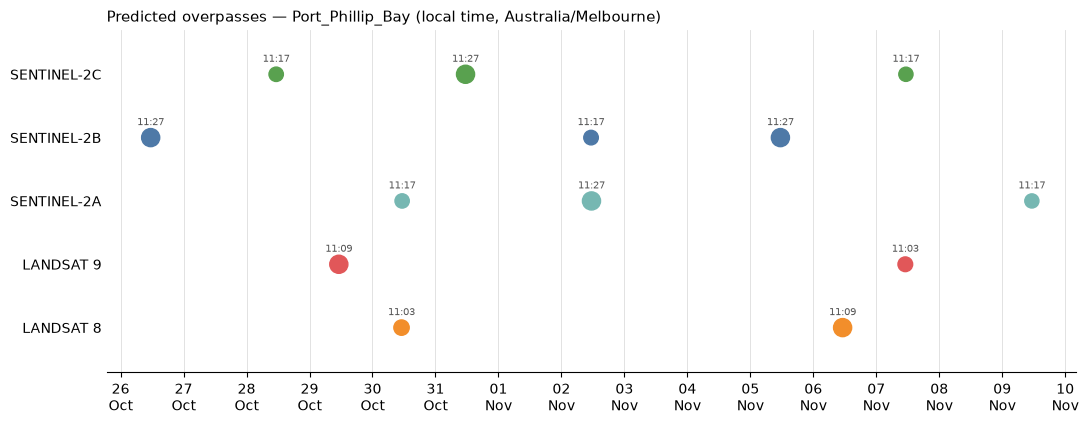

In [9]:
fig = plot_overpass_timeline(PASSES)

## 🗓️ Sentinel-2 Acquisition-Plan Cross-Check (Optional)
> ### **ESA Mission Planning KML → Planned Data-Takes → Pass Confirmation**

Orbital geometry says a satellite *can* image the ROI. Whether it *will* depends on the mission plan: Sentinel-2 does not acquire open ocean far from land, and **Sentinel-2A is in an extension campaign (to 31 Dec 2026) that covers selected regions only**. ESA publishes the planned data-takes for each unit as KML files roughly two weeks ahead.

---

### 🛰️ Sentinel-2 vs Landsat: How Acquisitions Are Decided
| | **Sentinel-2** | **Landsat 8 / 9** |
| :--- | :--- | :--- |
| **Policy** | Selective: land, coastal waters, islands and some enclosed seas. | [Long Term Acquisition Plan (LTAP)](https://www.usgs.gov/data/landsat-89-long-term-acquisition-plan-earths-continental-landmasses-and-near-shore-coastal): >99% of descending, daylit continental land and near-shore coastal scenes between 57°N and 57°S are scheduled; >91% poleward. |
| **Published schedule** | Per-unit [KML plans](https://sentinels.copernicus.eu/copernicus/sentinel-2/acquisition-plans) ~2 weeks ahead, re-issued when the plan changes. | [Landsat Acquisition Tool](https://landsat.usgs.gov/landsat_acq) / Acquisition Calendar: daily maps of scheduled path/rows. |
| **Not acquired by default** | Open ocean; Sentinel-2A outside its extension-campaign regions. | Open ocean, ascending (night) scenes, very low sun and polar LEAP scenes — [special request](https://www.usgs.gov/landsat-missions/landsat-acquisitions) only. |
| **Volume** | — | >1,500 scenes per day (Landsat 8 + 9). |
| **Cross-checked here** | ✔ (this section) | ✘ — shown as `n/a` |

**Scheduled ≠ usable.** For both missions, scheduled scenes are occasionally lost to spacecraft safe-modes, downlink gaps or processing failures; cloud cover is not forecast by either plan; and Landsat scenes with poorer geolocation are released as **Tier 2** rather than Tier 1.

**Simplified plan footprints.** ESA draws each data-take as a polygon joining the four corners of the strip, which can cut inside the true curved swath by several km. A `not planned` result on an **edge pass** can therefore be a footprint artefact — use the verification cell below.

---

### 📂 Plan Status Values
| Status | Meaning |
| :--- | :--- |
| **`planned (NOMINAL)`** | A nominal data-take of that unit overlaps the pass and intersects the ROI — data will be distributed. |
| **`planned (<other>)`** | Planned in a non-distributed mode (e.g. vicarious calibration). |
| **`not planned`** | The plan covers that date but no data-take over the ROI — no product expected. |
| **`no plan loaded`** | No downloaded plan covers that date yet (beyond ESA's planning horizon). |
| **`n/a`** | Landsat — not cross-checked here. USGS schedules >99% of daytime land and near-shore coastal scenes (LTAP) and publishes daily maps in the [Landsat Acquisition Tool](https://landsat.usgs.gov/landsat_acq). |

> ⚠️ **Note**: If the ESA page layout changes and the download fails, save the KML files manually from the [acquisition-plans page](https://sentinels.copernicus.eu/copernicus/sentinel-2/acquisition-plans) into `DATA/KML/` and re-run — any KML found there is used.

<div class="alert alert-block alert-warning" style="background-color:#fff3cd; color:#664d03; border:1px solid #ffe69c; border-left:6px solid #f0ad4e; border-radius:4px; padding:10px 16px; margin:6px 0;">
<b>⚠️ CAUTION — Interpreting the ESA plan status</b>
<ul style="margin:6px 0 0 0;">
  <li><code>planned (NOMINAL)</code> is the strongest confirmation available, but ESA revises plans — <b>re-run close to the date</b>.</li>
  <li><code>no plan loaded</code> means <b>unknown, not negative</b>: the date is beyond the published plans, or a plan file could not be downloaded.</li>
  <li><code>not planned</code> on an <b>edge pass</b> may be a simplified-footprint artefact — confirm with the verification cell below.</li>
  <li>Broken links on ESA's page are skipped with a warning; the passes they cover show <code>no plan loaded</code>.</li>
  <li><code>n/a</code> (Landsat) is low-risk for land and near-shore ROIs, but is not cross-checked — confirm critical dates in the <a href="https://landsat.usgs.gov/landsat_acq">Landsat Acquisition Tool</a>.</li>
</ul>
</div>

In [10]:
KML_DIR = Path("DATA") / "KML"
try:
    fetch_s2_acquisition_plans(KML_DIR,
                               start_utc=PASSES.attrs["window_start_utc"],
                               end_utc=PASSES.attrs["window_end_utc"])
except Exception as e:
    print(f"\x1b[93m⚠ Plan download failed ({type(e).__name__}: {e}). Using any KMLs already in {KML_DIR}.\x1b[0m")

PLANS = load_s2_acquisition_plans(KML_DIR)
if len(PLANS):
    PASSES = crosscheck_s2_acquisition_plan(PASSES, PLANS, ROI_GDF)
    display(summarise_overpasses(PASSES))
else:
    print("No acquisition plans available — continuing with geometric predictions only.")

✔ s2a_mp_acq__kml_20261015t150000_20261102t180000.kml (cached)
✔ s2b_mp_acq__kml_20261008t120000_20261026t150000.kml (cached)
⚠ s2b_mp_acq__kml_20261022t120000_20261109t150000: download failed on ESA's link (HTTPError). Skipping; save it manually into DATA\KML if the page link is fixed.
✔ s2c_mp_acq__kml_20261015t120000_20261102t150000.kml (cached)
⚠ 1 plan file(s) unavailable — passes they cover will show 'no plan loaded' (or rely on an older overlapping plan).
📄 2277 planned data-take(s) from 3 KML file(s): SENTINEL-2A 332, SENTINEL-2B 1038, SENTINEL-2C 907
🗓️  ESA plan cross-check: planned (NOMINAL): 4, no plan loaded: 4, not planned: 1


,Satellite,Local date,Local time (Australia/Melbourne),UTC offset,Overpass (UTC),Direction,ROI cover %,View angle °,Sun elev °,Expected,ESA plan
0,SENTINEL-2B,Mon 26 Oct 2026,11:27:24 – 11:27:36,+11:00,2026-10-26 00:27:29,Descending,100.0,5.24,56.4,✔,planned (NOMINAL)
1,SENTINEL-2C,Wed 28 Oct 2026,11:17:26 – 11:17:37,+11:00,2026-10-28 00:17:31,Descending,55.3,9.96,55.4,✔,planned (NOMINAL)
2,LANDSAT 9,Thu 29 Oct 2026,11:09:44 – 11:09:56,+11:00,2026-10-29 00:09:50,Descending,100.0,3.82,54.5,✔,n/a
3,LANDSAT 8,Fri 30 Oct 2026,11:03:41 – 11:03:53,+11:00,2026-10-30 00:03:47,Descending,65.9,6.49,53.8,✔,n/a
4,SENTINEL-2A,Fri 30 Oct 2026,11:17:33 – 11:17:44,+11:00,2026-10-30 00:17:39,Descending,54.4,10.00,56.0,✔,not planned
5,SENTINEL-2C,Sat 31 Oct 2026,11:27:21 – 11:27:33,+11:00,2026-10-31 00:27:26,Descending,100.0,5.14,57.7,✔,planned (NOMINAL)
6,SENTINEL-2B,Mon 02 Nov 2026,11:17:29 – 11:17:40,+11:00,2026-11-02 00:17:35,Descending,57.1,9.87,56.8,✔,no plan loaded
7,SENTINEL-2A,Mon 02 Nov 2026,11:27:28 – 11:27:40,+11:00,2026-11-02 00:27:33,Descending,100.0,5.10,58.3,✔,planned (NOMINAL)
8,SENTINEL-2B,Thu 05 Nov 2026,11:27:25 – 11:27:38,+11:00,2026-11-05 00:27:31,Descending,100.0,5.26,59.0,✔,no plan loaded
9,LANDSAT 8,Fri 06 Nov 2026,11:09:51 – 11:10:03,+11:00,2026-11-06 00:09:56,Descending,100.0,4.06,56.4,✔,n/a


#### 🔍 Verify a `not planned` Pass
Lists every data-take of that satellite **in progress at the pass time, ignoring footprint geometry**.

| Result | Meaning |
| :--- | :--- |
| **Empty table** | The satellite is not acquiring at that time — `not planned` is genuine. |
| **A `NOMINAL` row** | The simplified KML footprint missed the ROI — the pass is very likely acquired. |

In [11]:
ROW = 4   # index of the pass to verify in PASSES / the summary table

t, sat = PASSES.loc[ROW, "overpass_utc"], PASSES.loc[ROW, "satellite"]
if not sat.startswith("SENTINEL-2"):
    print(f"Row {ROW} is {sat} — only Sentinel-2 passes can be checked against ESA plans.")
elif PLANS.empty:
    print("No acquisition plans loaded.")
else:
    print(f"{sat} at {t:%Y-%m-%d %H:%M:%S} UTC")
    display(PLANS[(PLANS["satellite"] == sat)
                  & (PLANS["obs_start_utc"] <= t)
                  & (PLANS["obs_stop_utc"] >= t)].drop(columns="geometry"))

SENTINEL-2A at 2026-10-30 00:17:39 UTC


,satellite,plan_category,datatake_id,mode,obs_start_utc,obs_stop_utc,orbit_absolute,orbit_relative,plan_file,plan_start_utc,plan_end_utc


## 💾 Report Export
> ### **CSV (UTC + Local) → GeoPackage Footprints → Live-Tracker Page**

---

### 📋 Export Behaviour
* **CSV**: UTC columns are ISO-8601 with `Z`; local columns carry their explicit offset (`2026-10-26T11:27:30+11:00`), plus split `local_date`, `local_time` and `local_weekday` columns for spreadsheets. File name: `OUTPUT/overpasses_<roi>_<start>_<end>.csv`.
* **GeoPackage**: Swath strips with all attributes, for QGIS / ArcGIS.
* **Live tracker**: A standalone HTML page that propagates the orbits in the browser and counts down to these passes (see `p02_overpass_live_tracker.ipynb`).

<div class="alert alert-block alert-warning" style="background-color:#fff3cd; color:#664d03; border:1px solid #ffe69c; border-left:6px solid #f0ad4e; border-radius:4px; padding:10px 16px; margin:6px 0;">
<b>⚠️ CAUTION — The CSV is a snapshot</b>
<ul style="margin:6px 0 0 0;">
  <li>It reflects the TLEs and ESA plans available <b>at the time of this run</b> — regenerate it before relying on it for a field day.</li>
  <li>Keep <code>tle_age_days</code>, <code>edge_margin_km</code> and <code>esa_plan_status</code> when sharing: they carry the confidence of each row.</li>
  <li>Local times use the offset in force on each date (<code>utc_offset</code>); do not convert by hand with a fixed offset across a daylight-saving change.</li>
</ul>
</div>

In [12]:
OUTPUT_DIR = Path("OUTPUT")

csv_path = export_overpass_csv(PASSES, OUTPUT_DIR, expected_only=False)
gpkg_path = export_overpass_footprints(PASSES, OUTPUT_DIR / f"{csv_path.stem}_footprints.gpkg")
html_path = export_live_tracker_html(TLES, ROI_GDF, OUTPUT_DIR / "live_tracker.html", passes=PASSES)

display(pd.read_csv(csv_path).head())

💾 13 overpass(es) written to OUTPUT\overpasses_Port_Phillip_Bay_20261025_20261110.csv
💾 13 footprint(s) written to OUTPUT\overpasses_Port_Phillip_Bay_20261025_20261110_footprints.gpkg
🌐 Live tracker written to OUTPUT\live_tracker.html — open it in any browser.


,satellite,mission,sensor,norad_id,direction,imaging_expected,roi_coverage_pct,roi_entry_utc,overpass_utc,roi_exit_utc,duration_s,roi_entry_local,overpass_local,roi_exit_local,local_date,local_time,local_weekday,timezone,utc_offset,nadir_offset_km,roi_side_of_track,edge_margin_km,view_angle_deg,max_elevation_deg,sun_elevation_deg,sat_altitude_km,tle_epoch_utc,tle_age_days,note,esa_plan_status,esa_datatake_id,esa_relative_orbit
0,SENTINEL-2B,Sentinel-2,MSI,42063,Descending,True,100.0,2026-10-26T00:27:24Z,2026-10-26T00:27:29Z,2026-10-26T00:27:36Z,12.0,2026-10-26T11:27:24+11:00,2026-10-26T11:27:29+11:00,2026-10-26T11:27:36+11:00,2026-10-26,11:27:29,Monday,Australia/Melbourne,+11:00,73.8,E,71.2,5.24,84.1,56.4,804.0,2026-10-24T07:09:43Z,1.7,Nominal constellation (with S2C). Open ocean i...,planned (NOMINAL),50335-4,116.0
1,SENTINEL-2C,Sentinel-2,MSI,60989,Descending,True,55.3,2026-10-28T00:17:26Z,2026-10-28T00:17:31Z,2026-10-28T00:17:37Z,11.0,2026-10-28T11:17:26+11:00,2026-10-28T11:17:31+11:00,2026-10-28T11:17:37+11:00,2026-10-28,11:17:31,Wednesday,Australia/Melbourne,+11:00,141.4,W,3.6,9.96,78.8,55.4,804.1,2026-10-24T04:38:39Z,3.8,Nominal constellation (with S2B). Open ocean i...,planned (NOMINAL),11197-6,73.0
2,LANDSAT 9,Landsat,OLI-2/TIRS-2,49260,Descending,True,100.0,2026-10-29T00:09:44Z,2026-10-29T00:09:50Z,2026-10-29T00:09:56Z,12.0,2026-10-29T11:09:44+11:00,2026-10-29T11:09:50+11:00,2026-10-29T11:09:56+11:00,2026-10-29,11:09:50,Thursday,Australia/Melbourne,+11:00,48.0,E,44.5,3.82,85.8,54.5,717.7,2026-10-24T03:48:06Z,4.8,USGS acquires ~all daytime land and near-coast...,NaN,NaN,NaN
3,LANDSAT 8,Landsat,OLI/TIRS,39084,Descending,True,65.9,2026-10-30T00:03:41Z,2026-10-30T00:03:47Z,2026-10-30T00:03:53Z,12.0,2026-10-30T11:03:41+11:00,2026-10-30T11:03:47+11:00,2026-10-30T11:03:53+11:00,2026-10-30,11:03:47,Friday,Australia/Melbourne,+11:00,81.7,W,10.8,6.49,82.8,53.8,717.9,2026-10-24T06:16:22Z,5.7,USGS acquires ~all daytime land and near-coast...,NaN,NaN,NaN
4,SENTINEL-2A,Sentinel-2,MSI,40697,Descending,True,54.4,2026-10-30T00:17:33Z,2026-10-30T00:17:39Z,2026-10-30T00:17:44Z,11.0,2026-10-30T11:17:33+11:00,2026-10-30T11:17:39+11:00,2026-10-30T11:17:44+11:00,2026-10-30,11:17:39,Friday,Australia/Melbourne,+11:00,142.1,W,2.9,10.00,78.7,56.0,804.2,2026-10-24T07:19:55Z,5.7,Extension campaign (to 31 Dec 2026): selected ...,not planned,NaN,NaN
